# Capstone Project: Producto 2 (Inference)
## Valor Seguro: ¿cuánto vale la tranquilidad de un barrio?

**Integrantes:** Cajas, Sayari · Cantero, Juan · Torres, Jesús

---

## 1. Qué se hace en este notebook

El Producto 1 mostró que el precio por m² tiende a ser menor donde hay más delitos cerca. En este producto se construye un modelo de **clasificación** que, a partir de la ubicación, la seguridad de la zona y las características de un departamento en venta de CABA, estima si su precio por m² es **alto o bajo**. Después se compara esa estimación con el precio publicado para marcar los avisos que están fuera de lo esperado.

- **Entrada:** los datos del Producto 1 (`propiedades_final.csv` y `delitos_muestra.csv`).
- **Target (lo que se predice):** `precio_alto`. Vale 1 si el precio por m² es mayor que la mediana del conjunto de entrenamiento y 0 si no.
- **Salida:** un modelo guardado (`modelo_precio_m2.pkl`) y una función de inferencia que recibe avisos nuevos y devuelve la probabilidad de precio alto. Esa función es la que usa el Actor de Apify.

> **Regla de estructura:** el entrenamiento (secciones 5 a 8) vive solo en este notebook. El Actor de Apify es únicamente de inferencia y no incluye el batch iterator ni el entrenamiento.

## 2. Métricas

**Métrica del modelo (técnica):**
- **AUC-ROC (métrica principal):** mide qué tan bien el modelo ordena los avisos de precio bajo y de precio alto. 0,5 es como tirar una moneda y 1 es perfecto.
- **F1 y exactitud (secundarias):** qué proporción de avisos clasifica bien, mirando un corte de 0,5.
- La métrica principal se decidió antes de ver los resultados de prueba. Se usa AUC porque no depende del corte elegido ni de cuántos avisos hay de cada clase. El F1 y la exactitud sí dependen, y un modelo que dice "alto" para todos puede sacar un F1 alto sin saber nada.
- Se compara siempre contra una **línea base**: un modelo que no usa ninguna variable (AUC = 0,5).

**Métrica de negocio:**

> Reducir la cantidad de avisos que quien busca comprar tiene que revisar a mano, pasando de revisar todos a revisar solo los que el modelo marca como "barato para su zona" (candidatos a oportunidad) o "caro para su zona" (candidatos a negociar el precio), medido como el porcentaje de avisos que quedan para revisar sobre el total.

| Elemento | En este proyecto |
|---|---|
| Indicador concreto | Porcentaje de avisos marcados para revisar sobre el total |
| Dirección del cambio | Reducir (de revisar el 100 % de los avisos a revisar solo los marcados) |
| Acción asociada al modelo | Marcar cada aviso nuevo como "barato", "caro" o "en línea con su zona" según la diferencia entre su precio publicado y el que el modelo espera |

**ROI:** con los datos que existen no se puede calcular un retorno en dinero. No hay costos del cliente, tiempos de búsqueda ni operaciones cerradas, y estimarlo exigiría suposiciones. Lo que sí se mide con los datos es el porcentaje de la lista que queda para revisar (sección 10).

## Contenido

3. Carga de datos
4. Selección de variables (features)
5. Preprocesamiento y separación en entrenamiento y prueba
6. Batch iterator: 5 modelos candidatos
7. ¿Cuánto aportan los delitos?
8. Mejor modelo
9. Inferencia sobre avisos nuevos
10. Evaluación con la métrica de negocio
11. Conclusiones

## 3. Librerías y carga de datos

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix, roc_curve
from sklearn.neighbors import BallTree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

SEMILLA = 42

In [ ]:
propiedades = pd.read_csv("propiedades_final.csv")
delitos_muestra = pd.read_csv("delitos_muestra.csv")

print("Propiedades:", propiedades.shape, "| Delitos (muestra):", delitos_muestra.shape)
propiedades.head(3)

Propiedades: (990, 15) | Delitos (muestra): (2000, 10)


,id_aviso,barrio,lat,lon,precio_usd,moneda_original,expensas_ars,sup_total,sup_cubierta,ambientes,dormitorios,banos,precio_m2,delitos_1km,robos_1km
0,20724993,Palermo,-34.580,-58.408,2400000,USD,NaN,275.000,275.000,5.000,3.000,4.000,"8,727.273",38,20
1,20756959,Palermo,-34.583,-58.412,650000,USD,NaN,295.000,295.000,6.000,5.000,3.000,"2,203.390",59,23
2,18609245,Palermo,-34.583,-58.425,218000,USD,"571,000.000",110.000,95.000,5.000,4.000,3.000,"1,981.818",70,38


## 4. Selección de variables (features)

Se eligen **8 features** (el máximo permitido es 10). Se dividen según cómo entran al modelo:

| Entran de forma lineal (5) | Entran con una transformación no lineal (3) |
|---|---|
| `delitos_1km`, `robos_1km`, `banos`, `lat`, `lon` | `sup_total` (con logaritmo), `ambientes` (en tramos), `barrio` (categoría) |

**Por qué estas y no otras:**
- Las cinco lineales tienen una relación con el precio por m² que va en el mismo sentido con Pearson y con Spearman (sección 9.6 del Producto 1).
- `sup_total`, `ambientes` y `barrio` no tienen una relación en línea recta con el precio por m²: el precio ya está dividido por la superficie, los ambientes se agrupan en 1, 2, 3 y 4 o más, y el barrio es una categoría.
- Se descartan `sup_cubierta` y `dormitorios` porque repiten casi la misma información que `sup_total` y `ambientes` (correlaciones de 0,92 y 0,95).
- Se descarta `expensas_ars` por tener 24 % de valores vacíos y estar en pesos.
- Se descartan `id_aviso` y `moneda_original` (no aportan) y `precio_usd`: el target sale del precio por m², que se calcula con ese precio, así que usarlo sería hacer trampa.

In [ ]:
TARGET = "precio_m2"

# Features que entran de forma lineal (se escalan y listo)
FEATURES_LINEALES = ["delitos_1km", "robos_1km", "banos", "lat", "lon"]
# Features que necesitan una transformación no lineal
FEATURES_NO_LINEALES = ["sup_total", "ambientes", "barrio"]

FEATURES = FEATURES_LINEALES + FEATURES_NO_LINEALES
FEATURES_DELITOS = ["delitos_1km", "robos_1km"]

print(f"{len(FEATURES)} features:", FEATURES)
print("Vacíos en las features:", propiedades[FEATURES].isna().sum()[lambda s: s > 0].to_dict())

# Control: ninguna feature puede ser el target ni derivar de él
assert TARGET not in FEATURES and "precio_usd" not in FEATURES

X = propiedades[FEATURES].copy()
y = propiedades[TARGET].copy()

8 features: ['delitos_1km', 'robos_1km', 'banos', 'lat', 'lon', 'sup_total', 'ambientes', 'barrio']
Vacíos en las features: {'banos': 19, 'ambientes': 11}


## 5. Preprocesamiento y separación en entrenamiento y prueba

El preprocesamiento va dentro de un `Pipeline`, así se aplica igual al entrenar y al predecir con avisos nuevos:

- **Features lineales:** los vacíos (`banos`) se completan con la mediana y se escalan.
- **`sup_total`:** logaritmo y escalado.
- **`ambientes`:** se agrupa en 1, 2, 3 y 4 o más, y se convierte en categorías.
- **`barrio`:** una columna por barrio; los barrios con menos de 5 avisos se agrupan.

Se usan solo funciones de numpy y scikit-learn para que el modelo guardado se pueda cargar en el Actor sin código extra.

**Cómo se arma el target:** primero se separa el 20 % de los avisos para prueba y después se calcula el umbral (la mediana del precio por m²) **solo con el conjunto de entrenamiento**. Así la prueba no influye en cómo se define "precio alto".

In [ ]:
# Se usan solo funciones de numpy para que el modelo guardado se pueda cargar en el Actor sin código extra.

def crear_preprocesador(features):
    lineales = [f for f in FEATURES_LINEALES if f in features]
    partes = []
    if lineales:
        partes.append(("lineales",
                       Pipeline([("imputar", SimpleImputer(strategy="median")),
                                 ("escalar", StandardScaler())]),
                       lineales))
    partes.append(("superficie",
                   Pipeline([("imputar", SimpleImputer(strategy="median")),
                             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("escalar", StandardScaler())]),
                   ["sup_total"]))
    partes.append(("ambientes",
                   Pipeline([("imputar", SimpleImputer(strategy="median")),
                             # 1, 2, 3 y 4 o más ambientes, como categorías
                             ("tramos", FunctionTransformer(np.clip, kw_args={"a_min": 1, "a_max": 4}, feature_names_out="one-to-one")),
                             ("categorias", OneHotEncoder(handle_unknown="ignore"))]),
                   ["ambientes"]))
    partes.append(("barrio",
                   OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5),
                   ["barrio"]))
    return ColumnTransformer(partes)

preprocesador = crear_preprocesador(FEATURES)
preprocesador.fit_transform(X).shape

(990, 37)

In [ ]:
y_precio = propiedades[TARGET]
X_train, X_test, precio_train, precio_test = train_test_split(X, y_precio, test_size=0.20, random_state=SEMILLA)

# El umbral sale SOLO del conjunto de entrenamiento (para no usar información de prueba)
UMBRAL_USD_M2 = float(precio_train.median())
y_train = (precio_train > UMBRAL_USD_M2).astype(int)   # 1 = precio alto, 0 = precio bajo
y_test = (precio_test > UMBRAL_USD_M2).astype(int)

print(f"Umbral: {UMBRAL_USD_M2:,.0f} USD/m² (mediana del entrenamiento)")
print(f"Entrenamiento: {len(X_train)} avisos ({y_train.mean():.1%} de precio alto) | Prueba: {len(X_test)} avisos ({y_test.mean():.1%} de precio alto)")

Umbral: 2,313 USD/m² (mediana del entrenamiento)
Entrenamiento: 792 avisos (50.0% de precio alto) | Prueba: 198 avisos (55.1% de precio alto)


## 6. Batch iterator: 5 modelos candidatos

Un bucle entrena los mismos 5 modelos con las mismas features y los compara:

| Tipo | Modelo |
|---|---|
| Clásico 1 | Regresión logística |
| Clásico 2 | Árbol de decisión |
| Ensamble 1 | Random Forest |
| Ensamble 2 | Gradient Boosting |
| Red neuronal | MLP de scikit-learn |

Más una **línea base** (sin variables) como referencia. Cada modelo se evalúa con **validación cruzada de 5 partes** sobre el conjunto de entrenamiento y después con el conjunto de prueba, que no se toca hasta el final. El mejor se elige por el **AUC de la validación cruzada**, no por el de prueba, para no elegir mirando los datos de prueba.

In [ ]:
def candidatos():
    return {
        "Clásico 1: Regresión logística": LogisticRegression(max_iter=2000),
        "Clásico 2: Árbol de decisión": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=SEMILLA),
        "Ensamble 1: Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEMILLA),
        "Ensamble 2: Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=SEMILLA),
        "MLP (scikit-learn)": MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.01, max_iter=2000,
                                           early_stopping=True, random_state=SEMILLA),
    }

def batch_iterator(features, etiqueta):
    """Entrena los 5 candidatos (y una línea base) con validación cruzada y evalúa en prueba."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    modelos = {"Línea base: azar": DummyClassifier(strategy="prior"), **candidatos()}
    filas, ajustados = [], {}
    for nombre, modelo in modelos.items():
        pipe = Pipeline([("prep", crear_preprocesador(features)), ("modelo", modelo)])
        p_cv = cross_val_predict(pipe, X_train[features], y_train, cv=cv, method="predict_proba")[:, 1]
        pipe.fit(X_train[features], y_train)
        p_test = pipe.predict_proba(X_test[features])[:, 1]
        filas.append({
            "escenario": etiqueta, "modelo": nombre,
            "AUC_cv": roc_auc_score(y_train, p_cv),
            "F1_cv": f1_score(y_train, p_cv >= 0.5),
            "AUC_prueba": roc_auc_score(y_test, p_test),
            "F1_prueba": f1_score(y_test, p_test >= 0.5),
            "Exactitud_prueba": accuracy_score(y_test, p_test >= 0.5),
        })
        ajustados[nombre] = pipe
    return pd.DataFrame(filas), ajustados

res_con, modelos_con = batch_iterator(FEATURES, "Con delitos")
res_con.drop(columns="escenario").round(3)

,modelo,AUC_cv,F1_cv,AUC_prueba,F1_prueba,Exactitud_prueba
0,Línea base: azar,0.498,0.614,0.500,0.710,0.551
1,Clásico 1: Regresión logística,0.759,0.697,0.774,0.719,0.712
2,Clásico 2: Árbol de decisión,0.702,0.679,0.697,0.616,0.616
3,Ensamble 1: Random Forest,0.789,0.734,0.761,0.667,0.657
4,Ensamble 2: Gradient Boosting,0.787,0.719,0.778,0.696,0.682
5,MLP (scikit-learn),0.731,0.647,0.659,0.535,0.596


**Lectura.**

- **Todos los modelos superan la línea base** (AUC de 0,50). En validación cruzada, Random Forest (0,789) y Gradient Boosting (0,787) lideran, seguidos por la regresión logística (0,759), el MLP (0,731) y el árbol de decisión (0,702).
- **La línea base engaña con el F1.** Un modelo que dice "precio alto" para todos saca un F1 de 0,71 en prueba, solo porque el 55 % de los avisos de prueba son de precio alto. Por eso la métrica principal es el AUC y no el F1.
- **En prueba los resultados cambian un poco** (por ejemplo, la regresión logística llega a 0,774 y el MLP baja a 0,659), porque son solo 198 avisos. La elección del mejor modelo se hace con la validación cruzada, que usa más datos.

## 7. ¿Cuánto aportan los delitos?

Es la pregunta del proyecto. Se repite el batch iterator **sin** `delitos_1km` ni `robos_1km` y se compara el AUC de validación cruzada. Si el AUC con delitos es mayor, los delitos ayudan.

In [ ]:
FEATURES_SIN = [f for f in FEATURES if f not in FEATURES_DELITOS]
res_sin, modelos_sin = batch_iterator(FEATURES_SIN, "Sin delitos")

comparacion = (pd.concat([res_con, res_sin])
               .pivot(index="modelo", columns="escenario", values=["AUC_cv", "AUC_prueba"])
               .round(3))
comparacion["AUC_cv (con - sin)"] = comparacion[("AUC_cv", "Con delitos")] - comparacion[("AUC_cv", "Sin delitos")]
display(comparacion.drop(index="Línea base: azar").round(3))

AUC_cv              AUC_prueba  \
escenario                      Con delitos Sin delitos Con delitos   
modelo                                                               
Clásico 1: Regresión logística       0.759       0.748       0.774   
Clásico 2: Árbol de decisión         0.702       0.737       0.697   
Ensamble 1: Random Forest            0.789       0.778       0.761   
Ensamble 2: Gradient Boosting        0.787       0.783       0.778   
MLP (scikit-learn)                   0.731       0.731       0.659   

                                           AUC_cv (con - sin)  
escenario                      Sin delitos                     
modelo                                                         
Clásico 1: Regresión logística       0.782              0.011  
Clásico 2: Árbol de decisión         0.713             -0.035  
Ensamble 1: Random Forest            0.770              0.011  
Ensamble 2: Gradient Boosting        0.770              0.004  
MLP (scikit-learn)                   0.771              0.000

**Lectura.**

- **Los delitos aportan muy poco.** Con delitos el AUC de validación cruzada sube en 3 modelos (regresión logística y Random Forest, 0,011 cada uno; Gradient Boosting, 0,004), queda igual en el MLP y baja en el árbol de decisión (0,035).
- **En el mejor modelo** (Random Forest) el AUC pasa de 0,778 a 0,789 con delitos en validación cruzada, pero en prueba pasa de 0,770 a 0,761. Es una diferencia dentro del margen de error.
- **Por qué es tan chico:** `lat`, `lon` y `barrio` ya le dicen al modelo dónde está la propiedad, y la seguridad varía con la zona. Los delitos agregan poca información nueva una vez que se conoce la ubicación.
- **Qué significa:** la seguridad se asocia con el precio (Producto 1), pero para *clasificar* el precio de un aviso pesa mucho menos que la ubicación y las características de la propiedad. Es un resultado a reportar tal cual.

## 8. Mejor modelo

Se elige el candidato con el mayor AUC en validación cruzada, con las features completas (con delitos), y se evalúa en el conjunto de prueba. Como el conjunto de prueba es chico, se calcula también un **intervalo de confianza del 95 %** para el AUC, remuestreando la prueba 1.000 veces.

Mejor modelo (mayor AUC en validación cruzada): Ensamble 1: Random Forest
  Validación cruzada: AUC = 0.789 | F1 = 0.734
  Prueba:             AUC = 0.761 (IC 95 %: 0.69 a 0.83) | F1 = 0.667 | exactitud = 0.657
  Línea base (azar):  AUC = 0.500

Matriz de confusión (filas: real; columnas: predicho):
           pred. bajo  pred. alto
real bajo          62          27
real alto          41          68


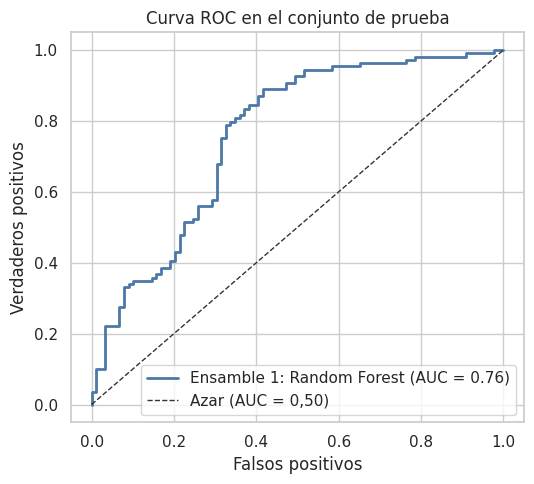

In [ ]:
# Métrica principal: AUC-ROC (se decide antes de mirar la prueba). El mejor es el de mayor AUC en validación cruzada.
candidatos_con = res_con[res_con["modelo"] != "Línea base: azar"].sort_values("AUC_cv", ascending=False)
nombre_mejor = candidatos_con.iloc[0]["modelo"]
mejor = modelos_con[nombre_mejor]
fila = candidatos_con.iloc[0]

p_test = mejor.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)
auc_test = roc_auc_score(y_test, p_test)
f1_test = f1_score(y_test, pred_test)
acc_test = accuracy_score(y_test, pred_test)

# Margen de error: se remuestrea el conjunto de prueba 1.000 veces
rng = np.random.default_rng(SEMILLA)
aucs = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test.iloc[idx].nunique() == 2:
        aucs.append(roc_auc_score(y_test.iloc[idx], p_test[idx]))
ic_inf, ic_sup = np.percentile(aucs, [2.5, 97.5])

print(f"Mejor modelo (mayor AUC en validación cruzada): {nombre_mejor}")
print(f"  Validación cruzada: AUC = {fila['AUC_cv']:.3f} | F1 = {fila['F1_cv']:.3f}")
print(f"  Prueba:             AUC = {auc_test:.3f} (IC 95 %: {ic_inf:.2f} a {ic_sup:.2f}) | F1 = {f1_test:.3f} | exactitud = {acc_test:.3f}")
print("  Línea base (azar):  AUC = 0.500")
print("\nMatriz de confusión (filas: real; columnas: predicho):")
print(pd.DataFrame(confusion_matrix(y_test, pred_test), index=["real bajo", "real alto"], columns=["pred. bajo", "pred. alto"]))

fpr, tpr, _ = roc_curve(y_test, p_test)
fig, eje = plt.subplots(figsize=(5.5, 5))
eje.plot(fpr, tpr, color="#4C78A8", linewidth=2, label=f"{nombre_mejor} (AUC = {auc_test:.2f})")
eje.plot([0, 1], [0, 1], color="#333333", linestyle="--", linewidth=1, label="Azar (AUC = 0,50)")
eje.set_xlabel("Falsos positivos"); eje.set_ylabel("Verdaderos positivos")
eje.set_title("Curva ROC en el conjunto de prueba"); eje.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [ ]:
UMBRAL_P_BAJO = 0.35   # por debajo, el modelo espera un precio BAJO para esa zona y características
UMBRAL_P_ALTO = 0.65   # por encima, el modelo espera un precio ALTO

paquete = {
    "modelo": mejor,
    "features": FEATURES,
    "target": "precio_alto",
    "umbral_usd_m2": UMBRAL_USD_M2,
    "umbral_p_bajo": UMBRAL_P_BAJO,
    "umbral_p_alto": UMBRAL_P_ALTO,
    "nombre_modelo": nombre_mejor,
    "radio_m": 1000,
}
with open("modelo_precio_m2.pkl", "wb") as f:
    pickle.dump(paquete, f)
print("Guardado: modelo_precio_m2.pkl")

Guardado: modelo_precio_m2.pkl


**Lectura.**

- **El mejor modelo es Random Forest:** AUC de 0,789 en validación cruzada y 0,761 en prueba (intervalo del 95 %: de 0,69 a 0,83), contra 0,50 de la línea base.
- **El AUC está en el rango de 0,7 a 0,8.** La exactitud (0,657) y el F1 (0,667) en prueba quedan algo por debajo de 0,7. Se reportan igual, y el AUC es la métrica principal por lo explicado en la sección 2.
- **Matriz de confusión:** de 198 avisos de prueba, acierta 130 (62 de precio bajo y 68 de precio alto). Se equivoca más en los de precio alto (41 clasificados como bajo) que en los de precio bajo (27 clasificados como alto).
- **El modelo ya está guardado** en `modelo_precio_m2.pkl`, junto con la lista de features y el umbral. Ese archivo es el que carga el Actor.

## 9. Inferencia sobre avisos nuevos

La función `predecir` es la que va al Actor de Apify. Recibe avisos nuevos con `lat`, `lon`, `sup_total`, `ambientes`, `banos` y `barrio`, y hace lo mismo que el Producto 1: calcula `delitos_1km` y `robos_1km` con `delitos_muestra.csv`, y aplica el modelo para devolver la probabilidad de precio alto.

Para probarla se toman los avisos de prueba, se les borran los delitos y el precio, y se verifica que el cruce recalculado coincida exactamente con el del Producto 1.

In [ ]:
RADIO_TIERRA_M = 6371000
RADIO_M = 1000

def cruzar_con_delitos(avisos, delitos, radio_m=RADIO_M):
    """Agrega delitos_1km y robos_1km a cada aviso, igual que en el Producto 1."""
    avisos = avisos.copy()
    puntos = np.radians(avisos[["lat", "lon"]].values)
    arbol = BallTree(np.radians(delitos[["Latitud", "Longitud"]].values), metric="haversine")
    avisos["delitos_1km"] = arbol.query_radius(puntos, r=radio_m / RADIO_TIERRA_M, count_only=True)
    robos = delitos[delitos["Tipo"].isin(["Robo", "Robo automotor"])]
    arbol_r = BallTree(np.radians(robos[["Latitud", "Longitud"]].values), metric="haversine")
    avisos["robos_1km"] = arbol_r.query_radius(puntos, r=radio_m / RADIO_TIERRA_M, count_only=True)
    return avisos

def predecir(avisos, delitos, paquete):
    """Recibe avisos nuevos (lat, lon, sup_total, ambientes, banos, barrio) y devuelve la probabilidad de precio alto."""
    salida = cruzar_con_delitos(avisos, delitos, paquete["radio_m"])
    salida["prob_precio_alto"] = paquete["modelo"].predict_proba(salida[paquete["features"]])[:, 1]
    salida["segmento_esperado"] = np.where(salida["prob_precio_alto"] >= 0.5, "Alto", "Bajo")
    return salida

def evaluar_aviso(fila, paquete):
    """Compara el segmento de precio publicado con el que el modelo espera para esa zona y características."""
    real_alto = fila["precio_m2_publicado"] > paquete["umbral_usd_m2"]
    if real_alto and fila["prob_precio_alto"] < paquete["umbral_p_bajo"]:
        return "Caro para su zona"
    if (not real_alto) and fila["prob_precio_alto"] > paquete["umbral_p_alto"]:
        return "Barato para su zona"
    return "En línea con su zona"

# Simulación: tomamos avisos de prueba y borramos lo que el modelo debe calcular solo
with open("modelo_precio_m2.pkl", "rb") as f:
    paquete = pickle.load(f)
nuevos = propiedades.loc[X_test.index, ["id_aviso", "barrio", "lat", "lon", "sup_total", "ambientes", "banos", "precio_m2"]]
resultado = predecir(nuevos.drop(columns="precio_m2"), delitos_muestra, paquete)
resultado["precio_m2_publicado"] = nuevos["precio_m2"]

# Control: el cruce recalculado tiene que coincidir con el del Producto 1
original = propiedades.loc[X_test.index, ["delitos_1km", "robos_1km"]]
assert (resultado["delitos_1km"].values == original["delitos_1km"].values).all()
assert (resultado["robos_1km"].values == original["robos_1km"].values).all()
print("✅ El cruce con delitos recalculado coincide con el del Producto 1")
resultado[["id_aviso", "barrio", "delitos_1km", "prob_precio_alto", "segmento_esperado", "precio_m2_publicado"]].head()

✅ El cruce con delitos recalculado coincide con el del Producto 1


,id_aviso,barrio,delitos_1km,prob_precio_alto,segmento_esperado,precio_m2_publicado
213,16661672,Villa Crespo,71,0.519,Alto,"2,641.509"
331,20874374,Villa del Parque,20,0.674,Alto,"2,100.592"
501,20253613,Belgrano,34,0.769,Alto,"2,625.000"
309,19471708,Recoleta,49,0.636,Alto,"1,608.696"
88,20290002,Almagro,80,0.126,Bajo,"1,730.769"


## 10. Evaluación con la métrica de negocio

Cada aviso se compara con lo que el modelo espera para su zona y sus características:
- **Caro para su zona:** el precio publicado es alto, pero el modelo esperaba uno bajo (probabilidad de precio alto menor a 0,35).
- **Barato para su zona:** el precio publicado es bajo, pero el modelo esperaba uno alto (probabilidad de precio alto mayor a 0,65).
- **En línea con su zona:** el resto.

Los umbrales de 0,35 y 0,65 se definieron antes de ver los resultados y se pueden cambiar: con umbrales más cerca de 0,5 se marcan más avisos.

In [ ]:
resultado["segmento_publicado"] = np.where(resultado["precio_m2_publicado"] > paquete["umbral_usd_m2"], "Alto", "Bajo")
resultado["evaluacion"] = resultado.apply(lambda f: evaluar_aviso(f, paquete), axis=1)

total = len(resultado)
conteo = resultado["evaluacion"].value_counts()
print(conteo.to_string())

revisar = resultado[resultado["evaluacion"] != "En línea con su zona"]
print(f"\nAvisos a revisar: {len(revisar)} de {total} ({len(revisar) / total:.1%}). La lista se reduce en {1 - len(revisar) / total:.1%}.")

print("\nPrecio por m² mediano publicado (USD):")
print(resultado.groupby("evaluacion")["precio_m2_publicado"].median().round(0).to_string())

salida_demo = resultado[["id_aviso", "barrio", "lat", "lon", "sup_total", "ambientes", "banos",
                         "delitos_1km", "robos_1km", "precio_m2_publicado", "segmento_publicado",
                         "prob_precio_alto", "segmento_esperado", "evaluacion"]].round(2)
salida_demo.to_csv("predicciones_demo.csv", index=False, encoding="utf-8-sig")
print("\nGuardado: predicciones_demo.csv", salida_demo.shape)

evaluacion
En línea con su zona    170
Barato para su zona      14
Caro para su zona        14

Avisos a revisar: 28 de 198 (14.1%). La lista se reduce en 85.9%.

Precio por m² mediano publicado (USD):
evaluacion
Barato para su zona    2,142.000
Caro para su zona      2,522.000
En línea con su zona   2,418.000

Guardado: predicciones_demo.csv (198, 14)


**Lectura.**

- **Lista a revisar:** de 198 avisos de prueba, el modelo marca 28 (14 "baratos" y 14 "caros para su zona"). Quien busca comprar pasa de revisar los 198 a revisar 28: la lista se reduce en 86 %.
- **Cómo usarlo:** una etiqueta es una señal para revisar un aviso, no una tasación. Un aviso "barato para su zona" puede serlo por algo que el modelo no ve (estado del departamento, antigüedad, un piso bajo).
- **Lo que no se puede afirmar:** con estos datos no hay forma de comprobar que los avisos marcados sean realmente oportunidades. Por eso la métrica de negocio mide cuánto se reduce la lista y no cuánto dinero se ahorra.

## 11. Conclusiones

### A. Qué se hizo
* **Datos:** se reutilizaron los datos del Producto 1: 990 propiedades en venta y la muestra de 2.000 delitos.
* **Problema:** clasificar si el precio por m² de un departamento es alto o bajo (umbral: la mediana del entrenamiento, 2.313 USD/m²).
* **Features:** 8 de un máximo de 10 (5 entran de forma lineal y 3 con una transformación no lineal).
* **Modelos:** un batch iterator con 5 candidatos y una línea base, con validación cruzada de 5 partes y evaluación en un conjunto de prueba aparte (792 avisos de entrenamiento y 198 de prueba).
* **Resultado:** el mejor modelo es Random Forest, con un AUC de 0,789 en validación cruzada y 0,761 en prueba.

### B. Qué se encontró
1. **El modelo distingue bien los avisos de precio alto y bajo.** Su AUC está en el rango de 0,7 a 0,8, muy por encima del azar (0,5).
2. **Los delitos aportan poco a la clasificación.** Mejoran el AUC de validación cruzada en 3 de 5 modelos, y en el mejor lo hacen en 0,011. La ubicación (`lat`, `lon`, `barrio`) ya recoge casi todo lo que informan los delitos.
3. **Esto no contradice el Producto 1.** Allí se vio que el precio por m² tiende a ser menor donde hay más delitos; acá se ve que, una vez que se conoce la ubicación, saber cuántos delitos hay cerca agrega poco.
4. **El modelo sirve para reducir la lista de avisos a revisar.** Marca 28 de 198 avisos (14 %) como fuera de lo esperado para su zona.

### C. Métrica de negocio y métrica del modelo

| Métrica | Valor |
|---|---|
| AUC en validación cruzada (principal) | 0,789 |
| AUC en prueba (principal) | 0,761 (intervalo del 95 %: 0,69 a 0,83) |
| Exactitud en prueba | 0,657 |
| F1 en prueba | 0,667 |
| Avisos a revisar sobre el total (negocio) | 14 % (28 de 198) |
| ROI | No calculable con los datos disponibles |

### D. Limitaciones
* Los delitos son de un solo mes (diciembre 2025) y los avisos son actuales.
* Los precios son de publicación, no de cierre de la operación.
* Convertir el precio en alto o bajo pierde información: un aviso apenas por encima del umbral cuenta igual que uno muy caro.
* Faltan variables que influyen mucho en el precio: estado, antigüedad, piso, amenities.
* El conjunto de prueba tiene 198 avisos y el intervalo del AUC es amplio (de 0,69 a 0,83). Los avisos de un mismo barrio se parecen entre sí y el resultado puede ser algo optimista.
* No hay forma de comprobar con estos datos que los avisos marcados sean oportunidades reales.
* El Mapa del Delito cuenta hechos, no hechos por habitante, y la muestra de delitos es de 2.000 sobre 7.809.

### E. Próximos pasos
* Pasar la función `predecir` al Actor de Apify (solo inferencia, con `ETL.py`, `preprocessing.py` y el modelo guardado). El Actor necesita `scikit-learn==1.6.1`, la misma versión con la que se entrenó.
* Conectar el Actor con Make para recibir avisos nuevos y llevar las predicciones al dashboard (`predicciones_demo.csv` sirve de ejemplo).

### F. Archivos de salida

| Archivo | Para qué |
|---|---|
| `modelo_precio_m2.pkl` | Modelo entrenado, lista de features y umbrales (lo carga el Actor) |
| `predicciones_demo.csv` | Predicciones de ejemplo para el dashboard de Insights |

In [ ]:
from google.colab import files

for nombre in ["modelo_precio_m2.pkl", "predicciones_demo.csv"]:
    files.download(nombre)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>